<a href="https://colab.research.google.com/github/JuanKevinder/Simulador-sEMG/blob/main/LABORATORIO_IBI_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ETAPA A**

---



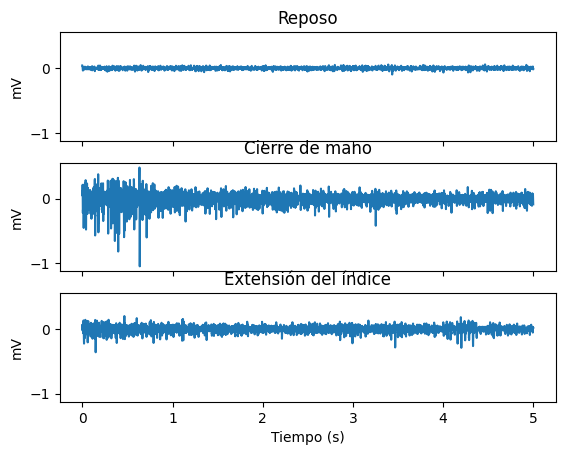

In [ ]:
!pip install wfdb #instala la libreria especializada en leer y escribir señales fisioogicas
import wfdb #importa la libreria anteriormente instalada
import numpy as np #libreria par realizar calculos matematicos
import matplotlib.pyplot as plt #libreria para realizar graficas
carpeta = "grabmyo/1.1.0/Session1/session1_participant1"
gestos = {"Reposo": 17, "Cierre de mano": 16, "Extensión del índice": 9}
canal = 11 # canal F12 → índice 11 en Python
senales = {}
for nombre_g, k in gestos.items():
 rec = wfdb.rdrecord(f"session1_participant1_gesture{k}_trial1", pn_dir=carpeta)
 senales[nombre_g] = rec.p_signal[:, canal]
fig, ax = plt.subplots(3, 1, sharex=True, sharey=True)
for a, (nombre_g, x) in zip(ax, senales.items()):
 a.plot(np.arange(len(x)) / rec.fs, x)
 a.set_title(nombre_g)
 a.set_ylabel("mV")
ax[-1].set_xlabel("Tiempo (s)")
plt.show()

***ETAPA B***

---



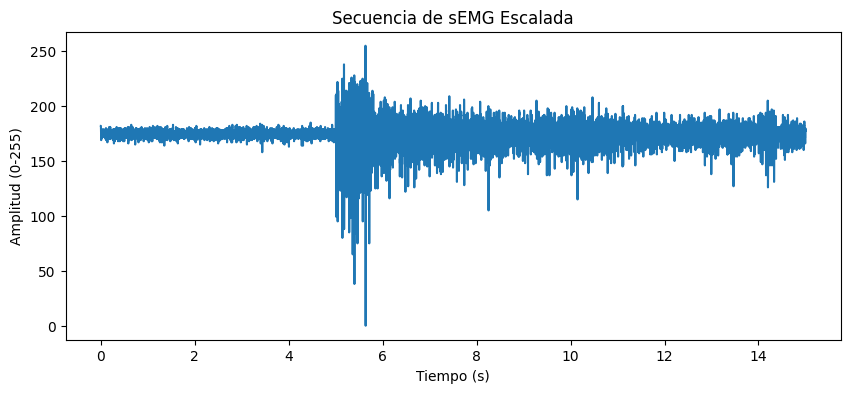

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Concatenación de los registros
secuencia = np.concatenate((
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del índice"]
))

# Escalado lineal entre 0 y 255 para toda la secuencia
val_min = np.min(secuencia)
val_max = np.max(secuencia)
secuencia_escalada = 255 * (secuencia - val_min) / (val_max - val_min)
secuencia_escalada = np.round(secuencia_escalada).astype(np.uint8)

# Gráfica de la secuencia escalada
plt.figure(figsize=(10, 4))
plt.plot(np.arange(len(secuencia_escalada)) / rec.fs, secuencia_escalada)
plt.title("Secuencia de sEMG Escalada")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (0-255)")
plt.show()

# Exportación del archivo de cabecera
with open("semg.h", "w") as f:
    f.write(f"const int N_SEMG = {len(secuencia_escalada)};\n")
    f.write(f"const int FS_SEMG = {rec.fs};\n")
    f.write("const uint8_t SEMG[] = {")
    f.write(", ".join(map(str, secuencia_escalada)))
    f.write("};\n")

# Descarga del archivo
files.download("semg.h")

La secuencia final cuenta con un total de 30 720 muestras, equivalentes a 15 segundos a una frecuencia de 2048 Hz.
El código concatena los tres estados en el orden específico: reposo, cierre de mano y extensión del índice.

In [1]:
!git clone https://github.com/JuanKevinder/Simulador-sEMG.git

Cloning into 'Simulador-sEMG'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [2]:
!git config --global user.name "JuanKevinder"
!git config --global user.email "juankevinder@gmail.com"
